# 02. Observables that include the population

**Question.** The 2PCF only sees positions. Which observable compares data and models on
the coupling between position and population?

**Data.** Belgian cities, with the SP mixtures marked as in notebook 01.
**Paper.** Not in the current version.
**Code.** `src/metadata_marks.py`.

Two observables are tested.
1. **Cumulative population profile M(r)**: population summed within a radius r of each
   node, averaged over nodes.
2. **People 2PCF**: 2PCF where each node counts in proportion to its population, so the
   2PCF of the inhabitants rather than of the cities.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent.parent           # repository root
sys.path.insert(0, str(ROOT / "src"))
import synthesis_utils as su
import metadata_marks as mm

# Fixed palette (Okabe-Ito, colour-blind safe). Each entity keeps the same colour in
# every notebook of the project. The population assignment variants (a), (b), (c)
# each have their own colour.
C = {"data": "#000000", "sp": "#0072B2", "rk": "#56B4E9", "split": "#CC79A7",
     "null": "#999999", "level": "#E69F00", "poisson": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

DATASET_NAME = "Belgium Cities"   # small (N=815) and carries a real population
ds = su.DATASETS[DATASET_NAME]
ld = su.load_dataset(ds)
xy_data, pop_data, geom = ld["xy_norm"], ld["pop_data"], ld["geom_norm"]
print(f"{DATASET_NAME}: N={ld['N_real']}, population min/median/max = "
      f"{pop_data.min():.0f}/{np.median(pop_data):.0f}/{pop_data.max():.0f}")

# Model: SP mixture + local density (same pipeline as notebook 01).
# The three population assignment variants are propagated:
#   (a) power law pop ∝ rho^beta, beta calibrated on the Zipf exponent
#   (b) rank matching: the real populations matched by rank of local density
#   (c) SP/background split: the |SP| largest populations on the fractal nodes, the
#       rest on the background, at random within each group (see notebook 01)
xy_sp, is_sp = su.build_sp_mixture(ds, ld["gdf_edge"], ld["bounds"], geom,
                                   ld["r_data"], ld["xi_data"],
                                   N_target=ld["N_real"], seed=su.SEED,
                                   return_labels=True)
rho = mm.local_density_knn(xy_sp, k=10)
beta_star, _ = mm.calibrate_beta_on_zipf(rho, su.fit_zipf_exponent(pop_data),
                                         pop_data.sum())
pop_sp = mm.pop_powerlaw(rho, beta_star, pop_data.sum())      # variant (a)
pop_sp_rk = mm.pop_rank_matching(rho, pop_data)               # variant (b)
pop_sp_c = mm.pop_split_sp_background(is_sp, pop_data, seed=0)  # variant (c)

# Nulls: shuffled marks on the data points, and Poisson positions with the data marks
rng = np.random.default_rng(0)
pop_shuf = rng.permutation(pop_data)
xy_pois = su.simulate_poisson(len(xy_data), geom, seed=1)
print(f"SP mixture: N={len(xy_sp)}, beta*={beta_star:.2f}")
print(f"Zipf exponent, data {su.fit_zipf_exponent(pop_data):.2f} | "
      f"(a) {su.fit_zipf_exponent(pop_sp):.2f} | "
      f"(b) {su.fit_zipf_exponent(pop_sp_rk):.2f} | "
      f"(c) {su.fit_zipf_exponent(pop_sp_c):.2f}")
print(f"(c): {is_sp.sum()} SP nodes / {len(is_sp)} "
      f"({100*is_sp.sum()/len(is_sp):.0f} %)")

  N=815  scale=272.8 km


  gamma_data=0.515  r0_norm=0.00390
Belgium Cities: N=815, population min/median/max = 19/8277/1235192


SP mixture: N=815, beta*=1.50
Zipf exponent, data 1.23 | (a) 1.32 | (b) 1.23 | (c) 1.23
(c): 190 SP nodes / 815 (23 %)


## 1. Cumulative population profile M(r)

M_i(r) = Σ_{j : d_ij ≤ r} pop_j, averaged over i. All variants have the same total
population, so the information is in the shape at small and intermediate r.

The log-log slope D_M does not measure the coupling. Swapping the two sums gives

$$\langle M(r)\rangle = \langle \mathrm{pop}\rangle \langle N(r)\rangle + \mathrm{Cov}\big(\mathrm{pop}_j, n_j(r)\big)$$

with n_j(r) the number of neighbours of j within r. The first term only depends on the
positions and sets the slope. The coupling enters through the covariance, which mostly
shifts the curve. On Belgium, D_M = 2.31 for the data and 2.26 ± 0.13 for the null with
shuffled marks (0.4σ).

Dividing by the geometric term removes it exactly:

$$M_{\mathrm{norm}}(r) = \frac{\langle M(r)\rangle}{\langle \mathrm{pop}\rangle \langle N(r)\rangle} = 1 + \frac{\mathrm{Cov}\big(\mathrm{pop}_j, n_j(r)\big)}{\langle \mathrm{pop}\rangle \langle N(r)\rangle}$$

M_norm = 1 without coupling (the null, by construction), and M_norm > 1 when large
populations are close to each other. It is dimensionless and does not depend on the mean
city size, so it can be compared across countries. It is noisy at small r, where
⟨N(r)⟩ → 0, and the raw covariance is shown in the third panel for these scales.

M_i(r) is evaluated exactly as a step function. A linear interpolation between
neighbours would overestimate M(r) by up to about 30 % at small r.

variant                           D_M   M_norm(peak)
Data                             2.31   1.74 at r=0.0055
SP + local density (a)           1.42   3.30 at r=0.0153
SP + rank matching (b)           1.46   3.13 at r=0.0119
SP + SP/background split (c)     1.40   2.35 at r=0.0055
Data, shuffled marks             2.28   1.10 at r=0.0033
Poisson + data marks             2.18   1.22 at r=0.0119

D_M: data 2.310 vs null 2.260 ± 0.132, gap 0.4 sigma
M_norm: null flat at 1.01, the gap of the data to 1 is the coupling


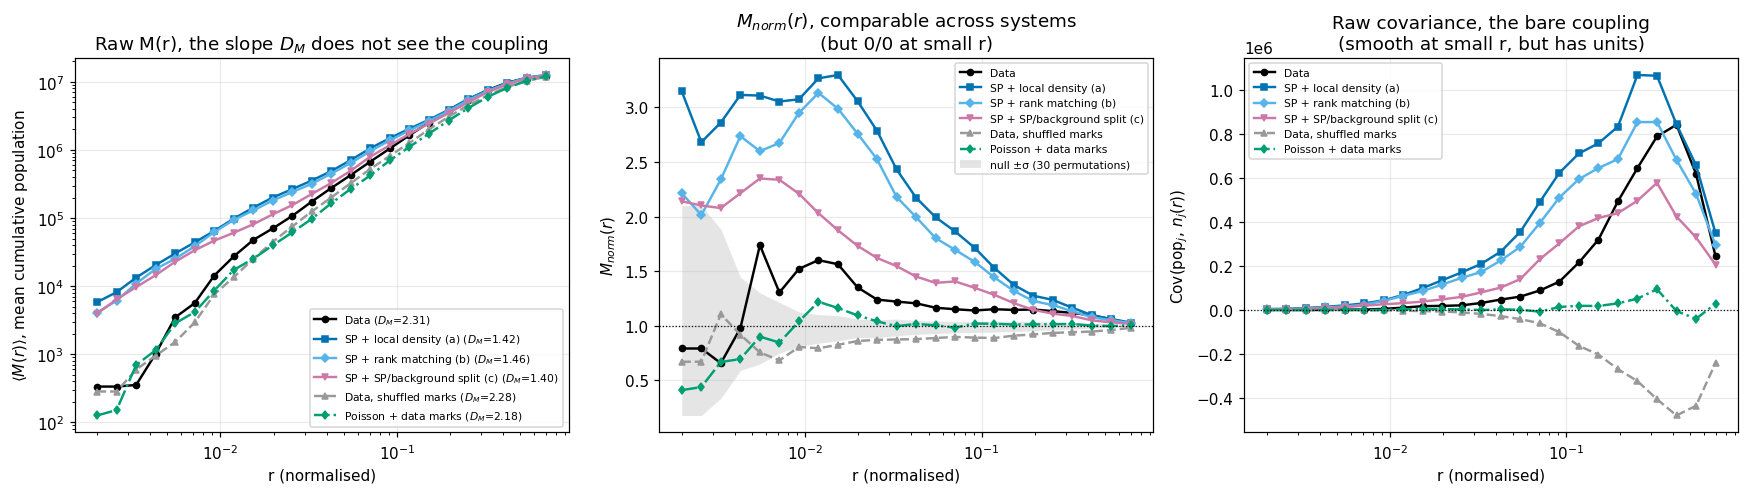

In [2]:
r_grid = np.logspace(np.log10(2e-3), np.log10(0.7), 24)
variants = {
    "Data":                        (xy_data, pop_data,  C["data"],    "o-"),
    "SP + local density (a)":      (xy_sp,   pop_sp,    C["sp"],      "s-"),
    "SP + rank matching (b)":      (xy_sp,   pop_sp_rk, C["rk"],      "D-"),
    "SP + SP/background split (c)": (xy_sp,  pop_sp_c,  C["split"],   "v-"),
    "Data, shuffled marks":        (xy_data, pop_shuf,  C["null"],    "^--"),
    "Poisson + data marks":        (xy_pois, pop_data,  C["poisson"], "d-."),
}
profiles, norms, COV, DM = {}, {}, {}, {}
for k, (xy, p, *_) in variants.items():
    M_norm, M, N = mm.normalized_population_profile(xy, p, r_grid)
    profiles[k], norms[k] = M, M_norm
    COV[k] = mm.covariance_profile(M, N, p)      # raw coupling, not normalised
    DM[k] = mm.mass_dimension(r_grid, M, a=1, b=16)

# Averaged null: M_norm expected flat at 1 (and a reference D_M to test D_M)
null_m, null_s, dm_null, dm_null_s = mm.shuffled_null_profile(
    xy_data, pop_data, r_grid, n_shuffle=30, seed=0)

print(f"{'variant':30s} {'D_M':>6s}   M_norm(peak)")
for k in variants:
    i_pk = np.nanargmax(norms[k][1:16]) + 1
    print(f"{k:30s} {DM[k]:6.2f}   {norms[k][i_pk]:.2f} at r={r_grid[i_pk]:.4f}")
print(f"\nD_M: data {DM['Data']:.3f} vs null {dm_null:.3f} ± {dm_null_s:.3f}"
      f", gap {abs(DM['Data']-dm_null)/dm_null_s:.1f} sigma")
print(f"M_norm: null flat at {np.nanmean(null_m):.2f}, the gap of the data to 1 is the coupling")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for k, (xy, p, c, st) in variants.items():
    axes[0].loglog(r_grid, profiles[k], st, ms=4, c=c, lw=1.6,
                   label=f"{k} ($D_M$={DM[k]:.2f})")
    axes[1].semilogx(r_grid, norms[k], st, ms=4, c=c, lw=1.6, label=k)
    axes[2].semilogx(r_grid, COV[k], st, ms=4, c=c, lw=1.6, label=k)
axes[0].set_xlabel("r (normalised)")
axes[0].set_ylabel("$\\langle M(r) \\rangle$, mean cumulative population")
axes[0].set_title("Raw M(r), the slope $D_M$ does not see the coupling")
axes[0].legend(fontsize=7)

axes[1].fill_between(r_grid, null_m - null_s, null_m + null_s, color=C["null"],
                     alpha=0.25, lw=0, label="null ±σ (30 permutations)")
axes[1].axhline(1, c="k", lw=0.8, ls=":")
axes[1].set_xlabel("r (normalised)")
axes[1].set_ylabel("$M_{norm}(r)$")
axes[1].set_title("$M_{norm}(r)$, comparable across systems\n(but 0/0 at small r)")
axes[1].legend(fontsize=7)

axes[2].axhline(0, c="k", lw=0.8, ls=":")
axes[2].set_xlabel("r (normalised)")
axes[2].set_ylabel("$\\mathrm{Cov}(\\mathrm{pop}_j,\\, n_j(r))$")
axes[2].set_title("Raw covariance, the bare coupling\n(smooth at small r, but has units)")
axes[2].legend(fontsize=7)
fig.tight_layout(); plt.show()

## 2. People 2PCF

Each node i is replaced by n_i ∝ pop_i nodes. Each pair then counts n_i n_j times, which
is the mark-weighted Landy-Szalay estimator (DD weighted by w_i w_j, DR by w_i, RR
unchanged). The weighted estimator avoids building the extended cloud. The next cell
checks that both give the same result.

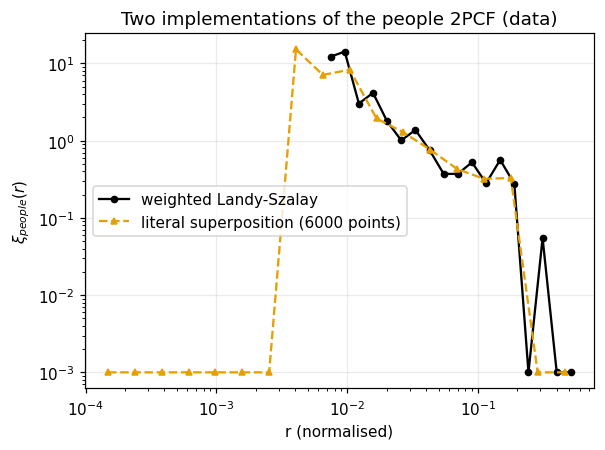

In [3]:
# Check: weighted estimator ≡ literal superposition (n_i ∝ pop_i)
r_w, xi_w = mm.compute_2pcf_people(xy_data, pop_data, geom)
xy_sup = mm.superpose_people(xy_data, pop_data, n_total=6000, seed=2)
r_sup, xi_sup = su.compute_2pcf_norm(xy_sup, geom)

fig, ax = plt.subplots(figsize=(5.6, 4.2))
ax.loglog(r_w, np.clip(xi_w, 1e-3, None), "o-", ms=4, c=C["data"],
          label="weighted Landy-Szalay")
ax.loglog(r_sup, np.clip(xi_sup, 1e-3, None), "^--", ms=4, c=C["level"],
          label="literal superposition (6000 points)")
ax.set_xlabel("r (normalised)"); ax.set_ylabel("$\\xi_{people}(r)$")
ax.set_title("Two implementations of the people 2PCF (data)")
ax.legend(); fig.tight_layout(); plt.show()

### Data, models and null

The unweighted 2PCF of the nodes is the reference. The null with shuffled marks should
give back ξ_people ≈ ξ_nodes.

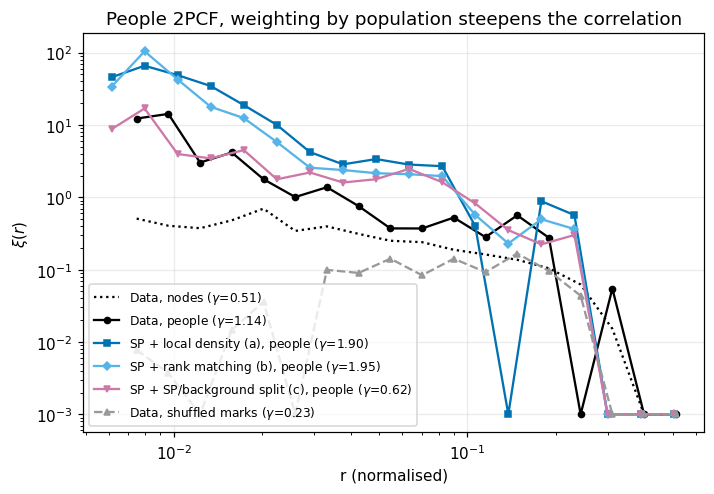

gamma_people (c), 10 draws: 0.666 ± 0.134   (the plotted curve is the draw with seed 0)


In [4]:
res_people = {
    "Data, people": mm.compute_2pcf_people(xy_data, pop_data, geom),
    "SP + local density (a), people": mm.compute_2pcf_people(xy_sp, pop_sp, geom),
    "SP + rank matching (b), people": mm.compute_2pcf_people(xy_sp, pop_sp_rk, geom),
    "SP + SP/background split (c), people": mm.compute_2pcf_people(xy_sp, pop_sp_c, geom),
    "Data, shuffled marks": mm.compute_2pcf_people(xy_data, pop_shuf, geom),
}
styles = {"Data, people": ("o-", C["data"]),
          "SP + local density (a), people": ("s-", C["sp"]),
          "SP + rank matching (b), people": ("D-", C["rk"]),
          "SP + SP/background split (c), people": ("v-", C["split"]),
          "Data, shuffled marks": ("^--", C["null"])}

fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.loglog(ld["r_data"], np.clip(ld["xi_data"], 1e-3, None), ":", c=C["data"],
          lw=1.5, label=f"Data, nodes ($\\gamma$={ld['gamma_fit']:.2f})")
gammas = {}
for k, (r, xi) in res_people.items():
    g, _ = su.fit_powerlaw_norm(r, xi)
    gammas[k] = g
    st, c = styles[k]
    lbl = f"{k} ($\\gamma$={g:.2f})" if g is not None else k
    ax.loglog(r, np.clip(xi, 1e-3, None), st, ms=4, c=c, label=lbl)
ax.set_xlabel("r (normalised)"); ax.set_ylabel("$\\xi(r)$")
ax.set_title("People 2PCF, weighting by population steepens the correlation")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

# (c) is random within each group: mean ± std of gamma_people over 10 draws
g_c_draws = []
for s_ in range(10):
    r_c, xi_c = mm.compute_2pcf_people(
        xy_sp, mm.pop_split_sp_background(is_sp, pop_data, seed=s_), geom)
    g_c_, _ = su.fit_powerlaw_norm(r_c, xi_c)
    if g_c_ is not None:
        g_c_draws.append(g_c_)
print(f"gamma_people (c), 10 draws: {np.mean(g_c_draws):.3f} ± {np.std(g_c_draws):.3f}"
      f"   (the plotted curve is the draw with seed 0)")

In [5]:
rows = [dict(observable="D_M (mass dimension) [not discriminant]", variant=k,
             value=round(v, 3)) for k, v in DM.items()]
# M_norm at its peak measures the coupling (1 = no coupling)
for k in variants:
    i_pk = int(np.nanargmax(norms[k][1:16]) + 1)
    rows.append(dict(observable="M_norm (peak, 1=no coupling)", variant=k,
                     value=round(float(norms[k][i_pk]), 3)))
rows += [dict(observable="gamma_people", variant=k,
              value=(round(g, 3) if g is not None else None))
         for k, g in gammas.items()]
rows += [dict(observable="gamma_nodes", variant="Data",
              value=round(ld["gamma_fit"], 3))]
df = pd.DataFrame(rows)
out_csv = ROOT / "out" / "02_metadata_observables_summary.csv"
df.to_csv(out_csv, index=False)
print(df.to_string(index=False))
print("->", out_csv)

                             observable                              variant  value
D_M (mass dimension) [not discriminant]                                 Data  2.310
D_M (mass dimension) [not discriminant]               SP + local density (a)  1.423
D_M (mass dimension) [not discriminant]               SP + rank matching (b)  1.458
D_M (mass dimension) [not discriminant]         SP + SP/background split (c)  1.403
D_M (mass dimension) [not discriminant]                 Data, shuffled marks  2.276
D_M (mass dimension) [not discriminant]                 Poisson + data marks  2.179
           M_norm (peak, 1=no coupling)                                 Data  1.738
           M_norm (peak, 1=no coupling)               SP + local density (a)  3.298
           M_norm (peak, 1=no coupling)               SP + rank matching (b)  3.134
           M_norm (peak, 1=no coupling)         SP + SP/background split (c)  2.349
           M_norm (peak, 1=no coupling)                 Data, shuffled marks

## Results (Belgium)

| | D_M | M_norm peak | γ_people |
|---|---|---|---|
| data | 2.31 | 1.74 (r ≈ 1.5 km) | 1.14 (nodes: 0.52) |
| SP + local density (a) | 1.42 | 3.30 | 1.90 |
| SP + rank matching (b) | 1.46 | 3.13 | 1.95 |
| SP + SP/background split (c) | 1.40 | 2.35 | 0.67 ± 0.13 (10 draws) |
| shuffled marks | 2.28 | 1.10 | 0.23 |

- D_M does not separate the data from the null. It is a geometric descriptor only.
- M_norm separates them. The null is flat at 1.01 and the data peak at 1.74.
- The marked SP over-couples by a factor of about 2, in agreement with Δγ (notebook 01)
  and γ_people. In the model the population is a deterministic function of the local
  density, while in the data the two are almost uncorrelated in rank (Spearman ≈ −0.02
  at k = 10).
- Without a node-by-node link between density and population, variant (c)
  under-couples.
- In the data, inhabitants are much more correlated than cities (γ_people ≫ γ_nodes).